<a href="https://colab.research.google.com/github/gilberto7martinezr-spec/AF4_Decision_Tree/blob/main/Medical_Image_Classification_Pneumonia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Intelligent Medical Image Classification
## Pneumonia detection in chest X-rays with a CNN (Transfer Learning, ResNet50)

**Course:** Artificial Intelligence | **Date:** November 17 2026

**Team:**

Leonardo Saavedra de León - 2093442

Rocío Gabriela Escalera Mireles - 2097046

Gilberto Rubén Cabral Martínez - 2110633

**Pipeline**
1. Data download and cleaning
2. Preprocessing (resize 224x224, scale to [0, 1], optional augmentation)
3. Model: ResNet50 pre-trained on ImageNet + custom classification head
4. Training (80% train / 20% test) and evaluation (accuracy, sensitivity, specificity, confusion matrix)
5. Model export (`.h5`)
6. Inference on unseen images with confidence score



## 1. Setup

In [ ]:
import os, glob, random, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Global configuration
IMG_SIZE = (224, 224)               # input size expected by ResNet50
BATCH_SIZE = 32
CLASS_NAMES = ["NORMAL", "PNEUMONIA"]   # label 0 = healthy, label 1 = pathological

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Dataset
**Chest X-Ray Images (Pneumonia)** (Kermany et al., Kaggle). Pediatric chest X-rays labelled `NORMAL` or `PNEUMONIA`.

The original dataset comes with its own train/val/test folders. Since the project requires an **80/20 split**, we first pool all images and then re-split them ourselves.

In [ ]:
!pip -q install kagglehub
import kagglehub

dataset_path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Downloaded to:", dataset_path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Downloaded to: /kaggle/input/chest-xray-pneumonia


In [ ]:
# Find the outermost folder that contains train/val/test (the dataset ships with a duplicated nested copy)
def find_dataset_root(base):
    for dirpath, dirnames, _ in os.walk(base):
        if {"train", "test", "val"}.issubset(set(dirnames)):
            return dirpath
    raise FileNotFoundError("train/test/val folders not found")

root = find_dataset_root(dataset_path)
print("Dataset root:", root)

all_paths, all_labels = [], []
for split in ["train", "val", "test"]:
    for cls_idx, cls in enumerate(CLASS_NAMES):
        found = glob.glob(os.path.join(root, split, cls, "*"))
        found = [f for f in found if f.lower().endswith((".jpeg", ".jpg", ".png"))]
        all_paths += found
        all_labels += [cls_idx] * len(found)

print("Total image files found:", len(all_paths))

Dataset root: /kaggle/input/chest-xray-pneumonia/chest_xray
Total image files found: 5856


## 3. Data cleaning
Criteria used to discard images:
- **Corrupted / truncated files** (cannot be opened or verified by PIL)
- **Too small** (shortest side < 64 px): not enough detail
- **Blank / near-uniform captures** (pixel standard deviation < 5): failed acquisitions
- **Exact duplicates** (same MD5 hash): avoids the same image appearing in both train and test

In [ ]:
def md5_of_file(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while True:
            block = f.read(chunk)
            if not block:
                break
            h.update(block)
    return h.hexdigest()

MIN_SIDE = 64
MIN_STD = 5.0

records, discarded, seen = [], [], set()

for path, label in zip(all_paths, all_labels):
    try:
        with Image.open(path) as im:
            im.verify()                                   # detects corrupted / truncated files
        with Image.open(path) as im:
            w, h = im.size
            gray = np.asarray(im.convert("L"), dtype=np.float32)
    except Exception:
        discarded.append((path, "corrupted"))
        continue

    if min(w, h) < MIN_SIDE:
        discarded.append((path, "too small"))
        continue
    if gray.std() < MIN_STD:
        discarded.append((path, "blank / low contrast"))
        continue

    digest = md5_of_file(path)
    if digest in seen:
        discarded.append((path, "exact duplicate"))
        continue
    seen.add(digest)

    records.append({"path": path, "label": label, "width": w, "height": h})

df = pd.DataFrame(records)
print(f"Kept: {len(df)} | Discarded: {len(discarded)}")
print(pd.Series([r for _, r in discarded]).value_counts().to_string() if discarded else "No images discarded")
print()
print(df["label"].map(lambda i: CLASS_NAMES[i]).value_counts())

Kept: 5824 | Discarded: 32
exact duplicate    32

label
PNEUMONIA    4245
NORMAL       1579
Name: count, dtype: int64


## 4. Exploratory analysis

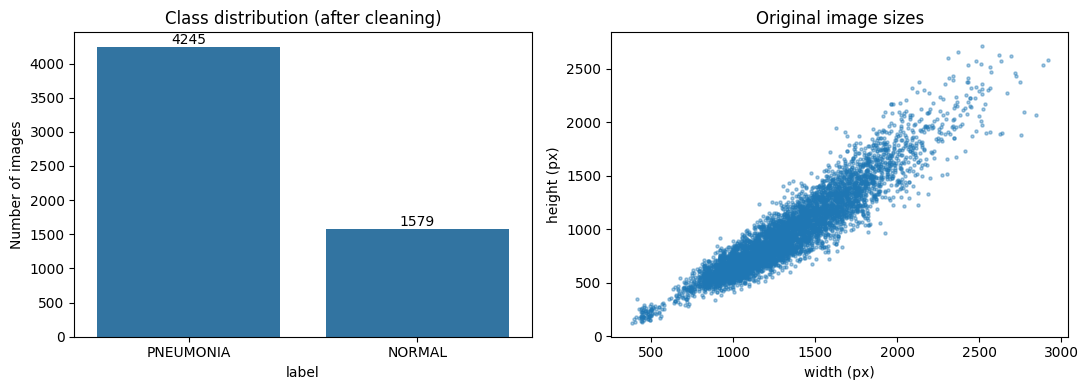

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Class distribution
counts = df["label"].map(lambda i: CLASS_NAMES[i]).value_counts()
sns.barplot(x=counts.index, y=counts.values, ax=axes[0])
axes[0].set_title("Class distribution (after cleaning)")
axes[0].set_ylabel("Number of images")
for i, v in enumerate(counts.values):
    axes[0].text(i, v, str(v), ha="center", va="bottom")

# Original image sizes (they are all different -> resizing is needed)
axes[1].scatter(df["width"], df["height"], s=5, alpha=0.4)
axes[1].set_title("Original image sizes")
axes[1].set_xlabel("width (px)")
axes[1].set_ylabel("height (px)")
plt.tight_layout()
plt.show()

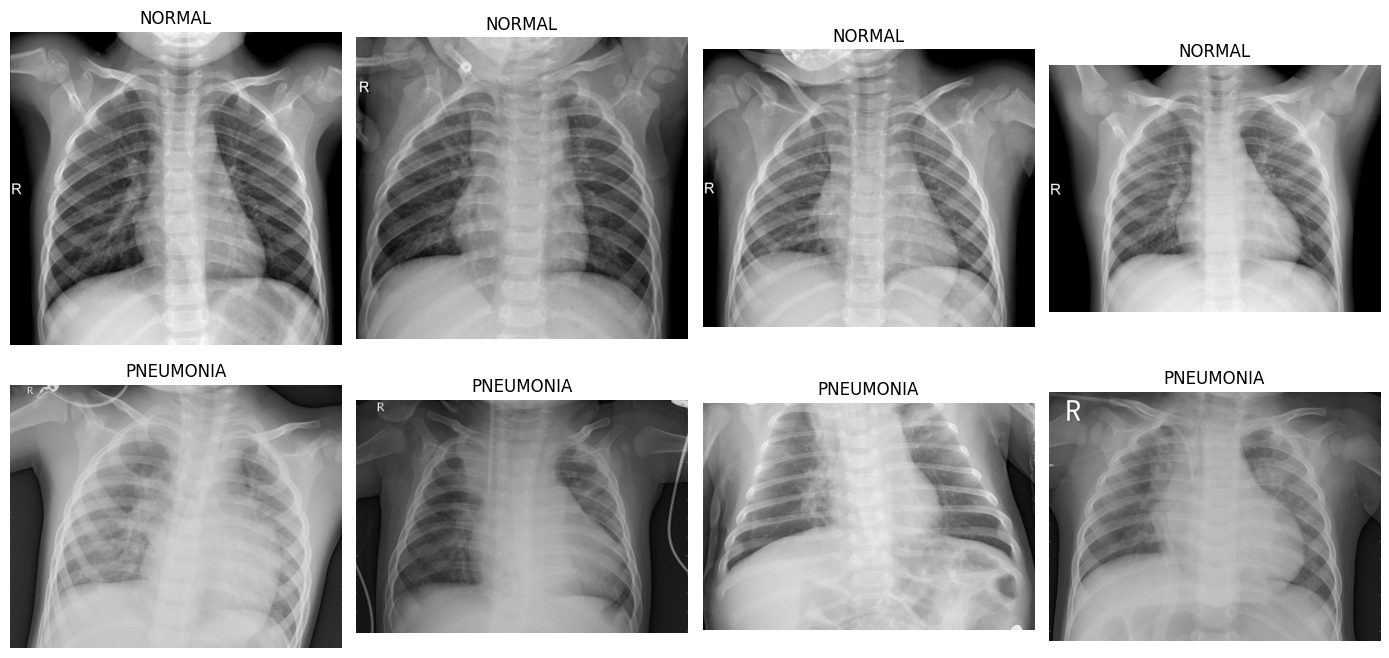

In [ ]:
# Sample images from each class
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, cls_idx in enumerate([0, 1]):
    samples = df[df["label"] == cls_idx].sample(4, random_state=SEED)
    for col, (_, r) in enumerate(samples.iterrows()):
        axes[row, col].imshow(Image.open(r["path"]).convert("L"), cmap="gray")
        axes[row, col].set_title(CLASS_NAMES[cls_idx])
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

## 5. Train / Test split (80% / 20%)
Stratified split so both sets keep the same class proportion. A small part (10%) of the training set is used as **validation** during training (early stopping / learning-rate scheduling). The 20% test set is only used for the final evaluation.

In [ ]:
train_df, test_df = train_test_split(
    df, test_size=0.20, stratify=df["label"], random_state=SEED)

train_df, val_df = train_test_split(
    train_df, test_size=0.10, stratify=train_df["label"], random_state=SEED)

for name, d in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    n_normal = (d["label"] == 0).sum()
    n_pneu = (d["label"] == 1).sum()
    print(f"{name:10s}: {len(d):5d} images | NORMAL={n_normal} | PNEUMONIA={n_pneu}")

# The dataset is imbalanced (more pneumonia than normal) -> class weights for the loss
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=train_df["label"].values)
class_weight = {0: weights[0], 1: weights[1]}
print("Class weights:", class_weight)

Train     :  4193 images | NORMAL=1137 | PNEUMONIA=3056
Validation:   466 images | NORMAL=126 | PNEUMONIA=340
Test      :  1165 images | NORMAL=316 | PNEUMONIA=849
Class weights: {0: np.float64(1.843887423043096), 1: np.float64(0.6860274869109948)}


## 6. Preprocessing pipeline
- **Resizing** to 224x224
- **Scale normalization**: pixels from [0, 255] to **[0, 1]** (`/ 255`)
- X-rays are grayscale; they are decoded as 3 channels (identical) to match the ResNet50 input

The same `load_image` function is reused at the end for the unseen images.

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)          # uniform size
    img = tf.cast(img, tf.float32) / 255.0        # scale to [0, 1]
    return img, tf.cast(label, tf.float32)

def make_dataset(dataframe, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (dataframe["path"].values, dataframe["label"].values))
    if shuffle:
        ds = ds.shuffle(len(dataframe), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)      # NOT shuffled: predictions keep the order of test_df

# Sanity check
x_batch, y_batch = next(iter(train_ds))
print("Batch shape:", x_batch.shape, "| pixel range:", float(tf.reduce_min(x_batch)), "-", float(tf.reduce_max(x_batch)))

Batch shape: (32, 224, 224, 3) | pixel range: 0.0 - 1.0


## 7. Model: Transfer Learning with ResNet50
**Why transfer learning?** ResNet50 was pre-trained on ImageNet (1.2M images). Its first layers already detect edges, textures and shapes that are useful in X-rays. Reusing those weights needs far less data and training time than a CNN trained from scratch, and usually generalizes better on medium-size medical datasets.

**Architecture**
- Data augmentation (active only during training): slight rotation, zoom and translation. Horizontal flips are intentionally **not** used because they would mirror the heart's position in a chest X-ray.
- Input in [0, 1] -> converted internally to the range ResNet50 expects (x255 and ImageNet mean subtraction)
- ResNet50 base (`include_top=False`)
- `GlobalAveragePooling2D` -> `Dropout(0.4)` -> `Dense(128, relu)` -> `Dropout(0.3)` -> `Dense(1, sigmoid)`

In [ ]:
def build_model():
    data_augmentation = keras.Sequential([
        layers.RandomRotation(0.04),
        layers.RandomZoom(0.10),
        layers.RandomTranslation(0.05, 0.05),
    ], name="augmentation")

    base = keras.applications.ResNet50(
        include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,))
    base.trainable = False                       # phase 1: frozen base

    inputs = keras.Input(shape=IMG_SIZE + (3,), name="image_0_1")
    x = data_augmentation(inputs)
    # Our images are in [0, 1]; ResNet50 expects 0-255 minus the ImageNet channel mean.
    # (Channels are identical in grayscale X-rays, so the BGR swap of preprocess_input is irrelevant.)
    x = layers.Rescaling(255.0, name="to_0_255")(x)
    x = layers.Normalization(mean=[103.939, 116.779, 123.68],
                             variance=[1.0, 1.0, 1.0], name="imagenet_mean")(x)
    x = base(x, training=False)                  # keep BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid", name="pneumonia_prob")(x)

    return keras.Model(inputs, outputs, name="pneumonia_resnet50"), base

model, base_model = build_model()
model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "pneumonia_resnet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_0_1 (InputLayer)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ to_0_255 (Rescaling)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ imagenet_mean (Normalization)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pneumonia_prob (Dense)          │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

## 8. Training
**Hyperparameters**
- Loss: Binary Cross-Entropy
- Optimizer: Adam
- Phase 1 (head only, base frozen): lr = 1e-3, up to 8 epochs
- Phase 2 (fine-tuning the last 30 layers of ResNet50): lr = 1e-5, up to 8 epochs
- Batch size: 32 | Class weights to compensate for class imbalance
- Callbacks: EarlyStopping (restores best weights) and ReduceLROnPlateau

In [ ]:
EPOCHS_HEAD = 8
EPOCHS_FINETUNE = 8

def compile_model(lr):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")])

def get_callbacks():
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, verbose=1),
    ]

# ---- Phase 1: train only the new classification head
compile_model(1e-3)
history_1 = model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
    class_weight=class_weight, callbacks=get_callbacks())

Epoch 1/8
132/132 ━━━━━━━━━━━━━━━━━━━━ 53s 271ms/step - accuracy: 0.8641 - auc: 0.9393 - loss: 0.3226 - val_accuracy: 0.9378 - val_auc: 0.9829 - val_loss: 0.1511 - learning_rate: 0.0010
Epoch 2/8
132/132 ━━━━━━━━━━━━━━━━━━━━ 30s 225ms/step - accuracy: 0.9120 - auc: 0.9715 - loss: 0.2152 - val_accuracy: 0.9571 - val_auc: 0.9878 - val_loss: 0.1246 - learning_rate: 0.0010
Epoch 3/8
132/132 ━━━━━━━━━━━━━━━━━━━━ 41s 223ms/step - accuracy: 0.9130 - auc: 0.9725 - loss: 0.2120 - val_accuracy: 0.9549 - val_auc: 0.9885 - val_loss: 0.1270 - learning_rate: 0.0010
Epoch 4/8
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.9251 - auc: 0.9741 - loss: 0.2105
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
132/132 ━━━━━━━━━━━━━━━━━━━━ 31s 233ms/step - accuracy: 0.9282 - auc: 0.9774 - loss: 0.1924 - val_accuracy: 0.9163 - val_auc: 0.9910 - val_loss: 0.1724 - learning_rate: 0.0010
Epoch 5/8
132/132 ━━━━━━━━━━━━━━━━━━━━ 30s 224ms/step - accuracy: 0.9299 - auc: 0.9817 - 

In [ ]:
# ---- Phase 2: fine-tune the last 30 layers of ResNet50 with a very small learning rate
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False          # keep BatchNorm statistics untouched

compile_model(1e-5)                      # must re-compile after changing trainable flags
history_2 = model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS_FINETUNE,
    class_weight=class_weight, callbacks=get_callbacks())

Epoch 1/8
132/132 ━━━━━━━━━━━━━━━━━━━━ 44s 257ms/step - accuracy: 0.9313 - auc: 0.9798 - loss: 0.1800 - val_accuracy: 0.9292 - val_auc: 0.9900 - val_loss: 0.1526 - learning_rate: 1.0000e-05
Epoch 2/8
132/132 ━━━━━━━━━━━━━━━━━━━━ 33s 249ms/step - accuracy: 0.9449 - auc: 0.9867 - loss: 0.1440 - val_accuracy: 0.9378 - val_auc: 0.9927 - val_loss: 0.1424 - learning_rate: 1.0000e-05
Epoch 3/8
132/132 ━━━━━━━━━━━━━━━━━━━━ 40s 241ms/step - accuracy: 0.9449 - auc: 0.9891 - loss: 0.1319 - val_accuracy: 0.9485 - val_auc: 0.9925 - val_loss: 0.1280 - learning_rate: 1.0000e-05
Epoch 4/8
132/132 ━━━━━━━━━━━━━━━━━━━━ 33s 248ms/step - accuracy: 0.9611 - auc: 0.9925 - loss: 0.1081 - val_accuracy: 0.9485 - val_auc: 0.9926 - val_loss: 0.1497 - learning_rate: 1.0000e-05
Epoch 5/8
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step - accuracy: 0.9674 - auc: 0.9942 - loss: 0.0932
Epoch 5: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.
132/132 ━━━━━━━━━━━━━━━━━━━━ 33s 248ms/step - accuracy: 0.9645

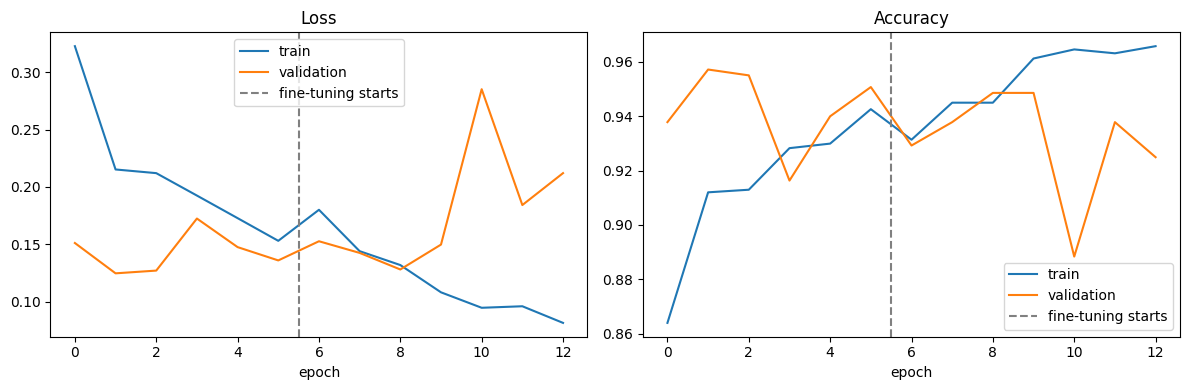

In [ ]:
# Training curves (both phases)
hist = {k: history_1.history[k] + history_2.history[k] for k in history_1.history}
phase_boundary = len(history_1.history["loss"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in zip(axes, ["loss", "accuracy"], ["Loss", "Accuracy"]):
    ax.plot(hist[metric], label="train")
    ax.plot(hist["val_" + metric], label="validation")
    ax.axvline(phase_boundary - 0.5, color="gray", linestyle="--", label="fine-tuning starts")
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

## 9. Evaluation on the test set (20%)
- **Sensitivity (recall of PNEUMONIA)**: fraction of sick patients correctly detected (minimizes false negatives)
- **Specificity (recall of NORMAL)**: fraction of healthy patients correctly identified (avoids unnecessary treatment)

Both are read directly from `classification_report`.

In [ ]:
y_prob = model.predict(test_ds).ravel()          # probability of PNEUMONIA
y_pred = (y_prob >= 0.5).astype(int)
y_true = test_df["label"].values

acc = accuracy_score(y_true, y_pred)
print(f"Test accuracy: {acc:.4f}\n")

print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True)
sensitivity = report["PNEUMONIA"]["recall"]      # true positive rate
specificity = report["NORMAL"]["recall"]         # true negative rate
print(f"Sensitivity (recall PNEUMONIA): {sensitivity:.4f}")
print(f"Specificity (recall NORMAL)   : {specificity:.4f}")
print(f"ROC AUC                       : {roc_auc_score(y_true, y_prob):.4f}")

37/37 ━━━━━━━━━━━━━━━━━━━━ 14s 317ms/step
Test accuracy: 0.9502

              precision    recall  f1-score   support

      NORMAL     0.8564    0.9810    0.9145       316
   PNEUMONIA     0.9925    0.9388    0.9649       849

    accuracy                         0.9502      1165
   macro avg     0.9244    0.9599    0.9397      1165
weighted avg     0.9556    0.9502    0.9512      1165

Sensitivity (recall PNEUMONIA): 0.9388
Specificity (recall NORMAL)   : 0.9810
ROC AUC                       : 0.9933


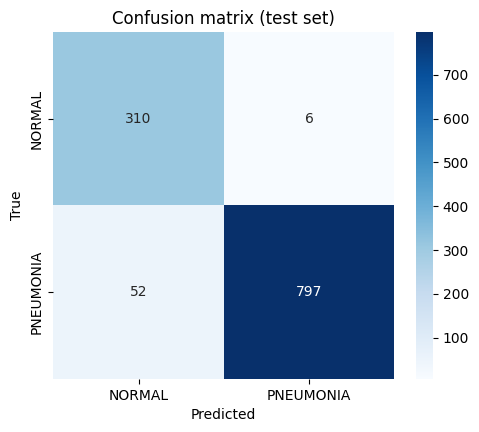

TN=310  FP=6  FN=52  TP=797


In [ ]:
# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix (test set)")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

## 10. Save the model (`.h5`)

In [ ]:
MODEL_PATH = "pneumonia_resnet50.h5"
model.save(MODEL_PATH)                  # architecture + weights in one HDF5 file
print("Saved:", MODEL_PATH, f"({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB)")

# Verify the exported file reproduces the same predictions
reloaded = keras.models.load_model(MODEL_PATH, compile=False)
sample_x, _ = next(iter(test_ds))
diff = np.abs(model.predict(sample_x, verbose=0) - reloaded.predict(sample_x, verbose=0)).max()
print("Max difference between original and reloaded model:", diff)

Saved: pneumonia_resnet50.h5 (213.4 MB)
Max difference between original and reloaded model: 0.0


In [ ]:
# Download the model to your computer (optional)
from google.colab import files
files.download(MODEL_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Inference with unseen images (live demo)
Upload **at least 5 chest X-rays that are NOT in the original dataset** (for example from Wikimedia Commons, Radiopaedia, or a different Kaggle chest X-ray dataset). They go through the **exact same** preprocessing (`load_image`: resize 224x224 + divide by 255).

In [ ]:
uploaded = files.upload()              # select 5 or more images
unseen_paths = list(uploaded.keys())
print(f"{len(unseen_paths)} images uploaded")

Saving 03-01-Infiltrat_Ausgang.png to 03-01-Infiltrat_Ausgang (2).png
Saving 04-01-Infiltrat_Ausgang.png to 04-01-Infiltrat_Ausgang (2).png
Saving 8e8bcfb6342117429b6fe136acbd76_big_gallery.jpeg to 8e8bcfb6342117429b6fe136acbd76_big_gallery (2).jpeg
Saving 90ecc64347f26e18d1d6aabafb1e366bff5f63f1c00f65efcac680fc9ebc9f20.png to 90ecc64347f26e18d1d6aabafb1e366bff5f63f1c00f65efcac680fc9ebc9f20 (2).png
Saving Human_bocavirus_1_pneumonia.jpg to Human_bocavirus_1_pneumonia (2).jpg
5 images uploaded


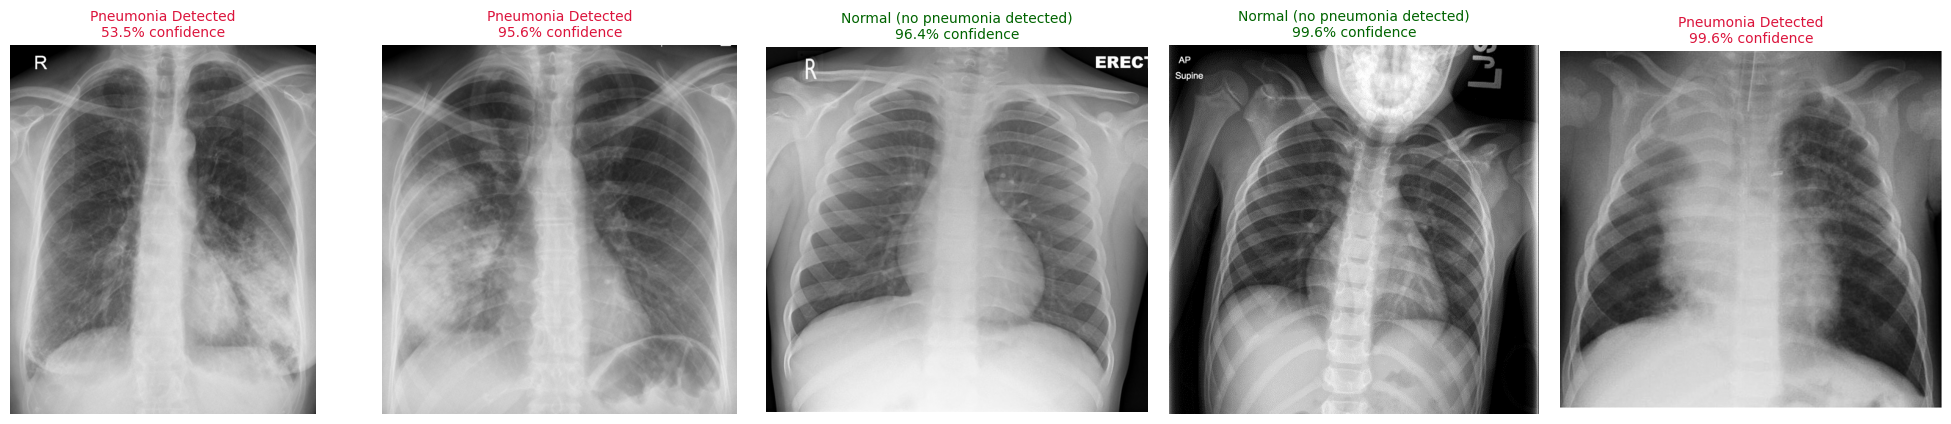

In [ ]:
def predict_image(path):
    img, _ = load_image(tf.constant(path), 0)            # same preprocessing as training
    prob = float(model.predict(tf.expand_dims(img, 0), verbose=0)[0][0])
    if prob >= 0.5:
        return "Pneumonia Detected", prob * 100
    return "Normal (no pneumonia detected)", (1 - prob) * 100

n = len(unseen_paths)
cols = min(n, 5)
rows = int(np.ceil(n / cols))
plt.figure(figsize=(4 * cols, 4.3 * rows))

for i, p in enumerate(unseen_paths):
    label, conf = predict_image(p)
    plt.subplot(rows, cols, i + 1)
    plt.imshow(Image.open(p).convert("L"), cmap="gray")
    plt.title(f"{label}\n{conf:.1f}% confidence", fontsize=10,
              color="crimson" if label.startswith("Pneumonia") else "darkgreen")
    plt.axis("off")

plt.tight_layout()
plt.show()